### Exercise 3 - Multi-Class, Same Network

A - Generate the Data

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

X, y = make_classification(
    n_samples=1500,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_repeated=0,
    n_classes=3,
    n_clusters_per_class=2,
    class_sep=1.0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training features: {X_train.shape}")
print(f"Test features: {X_test.shape}")

for label in np.unique(y):
    print(
        f"Class {label}: "
        f"{np.sum(y_train == label)} training samples, "
        f"{np.sum(y_test == label)} test samples"
    )

Training features: (1200, 4)
Test features: (300, 4)
Class 0: 399 training samples, 100 test samples
Class 1: 399 training samples, 100 test samples
Class 2: 402 training samples, 100 test samples


The dataset was divided into 1,200 training samples (80%) and 300 test samples (20%) using a stratified split with `random_state=42`. Each sample contains four informative features. The training set contains 399, 399, and 402 samples from Classes 0, 1, and 2, respectively, while the test set contains 100 samples per class.

B - Adapt the Network

For a single sample with output logits $u_j$, softmax gives

$$p_k=\frac{e^{u_k}}{\sum_j e^{u_j}},\qquad L=-\sum_k y_k\log p_k.$$

Here $y$ is one-hot encoded, so $\sum_k y_k=1$. The softmax derivative is

$$\frac{\partial p_k}{\partial u_j}=p_k(\delta_{kj}-p_j).$$

Using the chain rule,

$$\frac{\partial L}{\partial u_j}=\sum_k\left(-\frac{y_k}{p_k}\right)p_k(\delta_{kj}-p_j)=-y_j+p_j\sum_k y_k=p_j-y_j.$$

For mean categorical cross-entropy over $m$ samples, the output gradient is therefore

$$\boxed{\Delta^{(L)}=(P-Y)/m}.$$

The shared implementation uses this same output-gradient form for sigmoid with binary cross-entropy and softmax with categorical cross-entropy. Weight gradients, hidden-layer backpropagation, and parameter updates then use the same methods for both tasks.


In [36]:
class MLP:
    """Configurable MLP with tanh hidden layers."""

    def __init__(self, layer_sizes, rng, task="binary"):
        if task not in ("binary", "multiclass"):
            raise ValueError("task must be 'binary' or 'multiclass'.")

        if len(layer_sizes) < 3 or any(s < 1 for s in layer_sizes):
            raise ValueError("Use positive sizes and at least one hidden layer.")

        if task == "binary" and layer_sizes[-1] != 1:
            raise ValueError("Binary classification requires one output.")

        if task == "multiclass" and layer_sizes[-1] < 2:
            raise ValueError("Multiclass classification requires multiple outputs.")

        self.task = task
        self.n_outputs = layer_sizes[-1]
        self.weights = []
        self.biases = []

        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            limit = np.sqrt(6.0 / (n_in + n_out))
            self.weights.append(
                rng.uniform(-limit, limit, size=(n_in, n_out))
            )
            self.biases.append(np.zeros((1, n_out)))

    def output_activation(self, logits):
        if self.task == "binary":
            return np.exp(-np.logaddexp(0.0, -logits))

        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_values = np.exp(shifted)
        return exp_values / np.sum(exp_values, axis=1, keepdims=True)

    def encode_targets(self, y):
        if self.task == "binary":
            return np.asarray(y).reshape(-1, 1)

        # Integer labels 0, ..., K-1 become one-hot rows.
        labels = np.asarray(y, dtype=int).ravel()
        return np.eye(self.n_outputs)[labels]

    def forward(self, X):
        activations = [X]

        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            z = activations[-1] @ W + b
            activations.append(np.tanh(z))

        logits = (
            activations[-1] @ self.weights[-1] + self.biases[-1]
        )
        activations.append(self.output_activation(logits))

        return activations, logits

    def loss(self, logits, y):
        targets = self.encode_targets(y)

        if self.task == "binary":
            return float(np.mean(
                np.logaddexp(0.0, logits) - targets * logits
            ))

        # Stable log-softmax, without taking log of rounded probabilities.
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        log_probs = shifted - np.log(
            np.sum(np.exp(shifted), axis=1, keepdims=True)
        )

        return float(-np.mean(np.sum(targets * log_probs, axis=1)))

    def backward(self, activations, y):
        targets = self.encode_targets(y)
        m = targets.shape[0]

        # Valid for both supported activation–loss pairs.
        delta = (activations[-1] - targets) / m

        dW = [None] * len(self.weights)
        db = [None] * len(self.biases)

        for layer in range(len(self.weights) - 1, -1, -1):
            dW[layer] = activations[layer].T @ delta
            db[layer] = np.sum(delta, axis=0, keepdims=True)

            if layer > 0:
                delta = (
                    delta @ self.weights[layer].T
                ) * (1 - activations[layer] ** 2)

        return dW, db

    def update(self, dW, db, learning_rate):
        for layer in range(len(self.weights)):
            self.weights[layer] -= learning_rate * dW[layer]
            self.biases[layer] -= learning_rate * db[layer]

    def fit(self, X, y, learning_rate=0.1, epochs=2000):
        history = []

        for _ in range(epochs):
            activations, _ = self.forward(X)
            dW, db = self.backward(activations, y)
            self.update(dW, db, learning_rate)

            _, logits = self.forward(X)
            history.append(self.loss(logits, y))

        return np.array(history)

    def predict_proba(self, X):
        activations, _ = self.forward(X)
        probabilities = activations[-1]

        if self.task == "binary":
            return probabilities.ravel()

        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)

        if self.task == "binary":
            return (probabilities >= 0.5).astype(int)

        return np.argmax(probabilities, axis=1)

In [37]:
model_multiclass = MLP([4, 8, 3], rng, task="multiclass")

C - Train and Evaluate

In [38]:
learning_rate = 0.1
epochs = 2000

training_loss_multiclass = model_multiclass.fit(
    X_train,
    y_train,
    learning_rate=learning_rate,
    epochs=epochs
)

y_pred_multiclass = model_multiclass.predict(X_test)
multiclass_accuracy = np.mean(y_pred_multiclass == y_test)

print("Architecture: [4, 8, 3]")
print(f"Learning rate: {learning_rate}")
print(f"Epochs: {epochs}")
print(f"Test accuracy: {multiclass_accuracy:.2%}")
print(f"Final training loss: {training_loss_multiclass[-1]:.6f}")

Architecture: [4, 8, 3]
Learning rate: 0.1
Epochs: 2000
Test accuracy: 84.67%
Final training loss: 0.395544


| Setting | Value |
|---|---|
| Architecture | **4 → 8 → 3** |
| Hidden activation | `tanh` |
| Output activation | Softmax |
| Loss | Categorical cross-entropy |
| Weight initialization | Xavier uniform |
| Optimizer | Full-batch gradient descent |
| Batch size | 1,200 |
| Learning rate | 0.1 |
| Epochs | 2,000 |
| Final training loss | 0.395544 |
| Test accuracy | 84.67% |

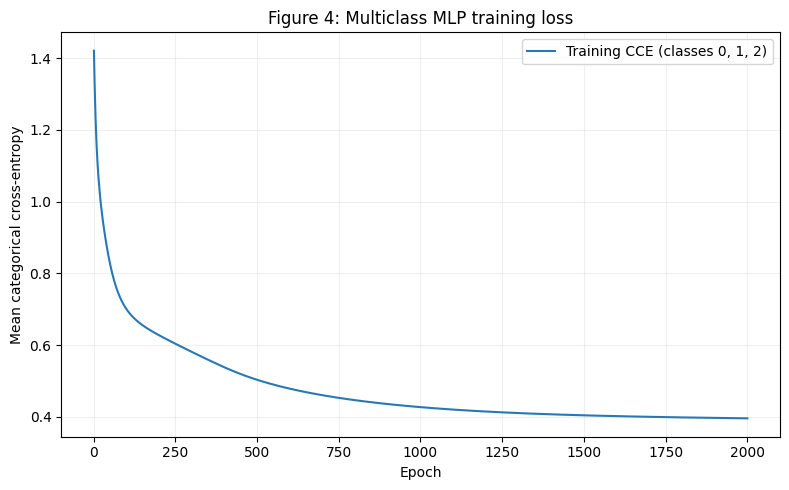

In [39]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    np.arange(1, epochs + 1),
    training_loss_multiclass,
    color="#2878b5",
    label="Training CCE (classes 0, 1, 2)"
)

ax.set_title("Figure 4: Multiclass MLP training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean categorical cross-entropy")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("./figures/figure4.png", dpi=180)
plt.show()

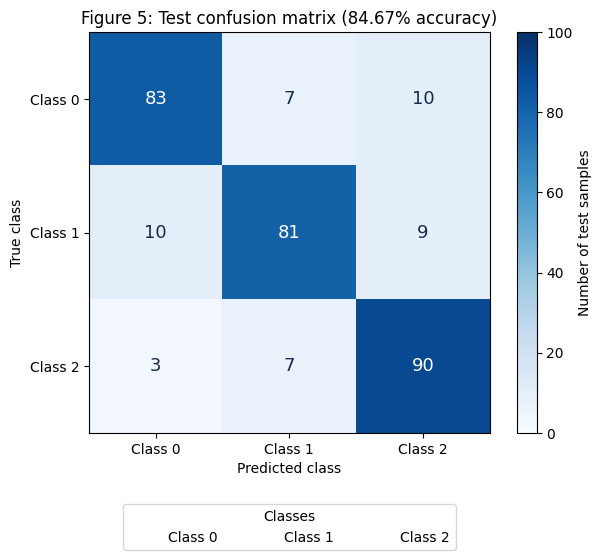

In [40]:
from sklearn.metrics import confusion_matrix
from matplotlib.patches import Patch

labels = [0, 1, 2]
class_names = ["Class 0", "Class 1", "Class 2"]

cm = confusion_matrix(
    y_test,
    y_pred_multiclass,
    labels=labels
)

fig, ax = plt.subplots(figsize=(6.5, 5.5))

image = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Number of test samples")

ax.set_xticks(labels)
ax.set_yticks(labels)
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(
    f"Figure 5: Test confusion matrix "
    f"({multiclass_accuracy:.2%} accuracy)"
)

for row in range(3):
    for col in range(3):
        ax.text(
            col, row, str(cm[row, col]),
            ha="center",
            va="center",
            fontsize=13,
            color="white" if cm[row, col] > 50 else "#172b4d"
        )

ax.legend(
    handles=[
        Patch(facecolor="none", edgecolor="none", label=name)
        for name in class_names
    ],
    title="Classes",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3
)

fig.tight_layout()
fig.savefig("./figures/figure5.png", dpi=180)
plt.show()

D - Analysis

In [42]:
from sklearn.linear_model import LogisticRegression

baseline_multiclass = LogisticRegression(
    random_state=42,
    max_iter=2000
)

baseline_multiclass.fit(X_train, y_train)
y_pred_baseline = baseline_multiclass.predict(X_test)

baseline_accuracy = np.mean(y_pred_baseline == y_test)
print(f"Logistic-regression test accuracy: {baseline_accuracy:.2%}")
print(f"Correct baseline predictions: {np.sum(y_pred_baseline == y_test)}/{len(y_test)}")
print(f"Accuracy improvement: {100 * (multiclass_accuracy - baseline_accuracy):.2f} percentage points")
print(f"Additional correct predictions: {np.sum(y_pred_multiclass == y_test) - np.sum(y_pred_baseline == y_test)}")

for first in range(3):
    for second in range(first + 1, 3):
        total = cm[first, second] + cm[second, first]
        print(f"Classes {first} and {second}: {total} combined errors")


Logistic-regression test accuracy: 66.33%
Correct baseline predictions: 199/300
Accuracy improvement: 18.33 percentage points
Additional correct predictions: 55
Classes 0 and 1: 17 combined errors
Classes 0 and 2: 13 combined errors
Classes 1 and 2: 16 combined errors


Figure 5 has the following confusion matrix; rows are true labels and columns are predicted labels:

| True class / Predicted class | Class 0 | Class 1 | Class 2 |
|---|---:|---:|---:|
| Class 0 | **83** | 7 | 10 |
| Class 1 | 10 | **81** | 9 |
| Class 2 | 3 | 7 | **90** |

The diagonal sums to 254 correct predictions out of 300, giving 84.67% test accuracy. Because each class has 100 test samples, the recalls are 83% for Class 0, 81% for Class 1, and 90% for Class 2.

Classes 0 and 1 are the most confused pair, with 17 errors across both directions: 7 true Class 0 samples are predicted as Class 1, and 10 true Class 1 samples are predicted as Class 0. Classes 1 and 2 have 16 combined errors (9 + 7), and Classes 0 and 2 have 13 (10 + 3). The largest single off-diagonal count is 10, shared by true Class 0 predicted as Class 2 and true Class 1 predicted as Class 0.

The dataset contains six clusters in four informative dimensions, with two clusters assigned to each class. Each class therefore occupies multiple regions in the original feature space. Clusters of different classes may be close or overlap; in this run, the higher confusion between Classes 0 and 1 is consistent with less effective separation of some of their samples. This is a plausible explanation, rather than a conclusion about specific clusters: the confusion matrix does not identify cluster membership or establish which clusters overlap. Informative features help distinguish classes but do not guarantee perfect separation. The generator also includes its default small amount of label noise.

The logistic-regression baseline achieves 66.33% accuracy, or 199/300 correct predictions. The MLP achieves 84.67%, or 254/300, an improvement of 18.33 percentage points and 55 additional correct predictions.

Logistic regression learns linear class scores and flat pairwise decision boundaries in the original four-dimensional space. The MLP's eight-neuron `tanh` hidden layer learns a nonlinear transformation of those features, enabling more flexible boundaries that better accommodate the two-cluster structure within each class. Residual errors remain, consistent with imperfect separation and possible overlap or label noise.
